# 02 - Baselines

Predict the intent of a question. Three baselines:
- **Majority**: always the most common intent, the floor.
- **BM25**: keyword search over the training questions, the usual non-ML approach for FAQ matching.
- **TF-IDF + logistic regression**: a classic trained classifier.

Fit on train, tune on val, report test once. Held-out intents aren't used here.

## 0. Setup (local or Colab)

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Eddydev-ALU/ML_Technique_I_Summative_sti-qa-assistant.git"

if IN_COLAB:
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rank_bm25==0.2.2", "openpyxl==3.1.5"], check=True)
    subprocess.run([sys.executable, "-m", "src.download_data"], check=True)
    subprocess.run([sys.executable, "-m", "src.data_prep"], check=True)
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /Users/apple/Documents/ML_Technique_I_Summative_frontline-health-qa


In [2]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import BM25Baseline, MajorityBaseline, TfidfLogRegBaseline
from src.data_prep import load_prepared
from src.evaluate import per_category_accuracy, ranking_metrics, save_result

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 100)

## 1. Load the prepared data

In [3]:
questions, answer_bank = load_prepared()
train = questions[questions["split"] == "train"].reset_index(drop=True)
val = questions[questions["split"] == "val"].reset_index(drop=True)
test = questions[questions["split"] == "test"].reset_index(drop=True)

print(questions["split"].value_counts().to_string())
print("\nIntents in train:", train["intent_id"].nunique())
print("Val/test intents missing from train:",
      len(set(val["intent_id"]) - set(train["intent_id"])), "/", len(set(test["intent_id"]) - set(train["intent_id"])))

split
train       1477
held_out     381
test         333
val          311

Intents in train: 98
Val/test intents missing from train: 0 / 0


In [4]:
def evaluate(model, data):
    """Score a dataset with a fitted model and compute ranking metrics."""
    index = {intent: j for j, intent in enumerate(model.intents)}
    true_idx = data["intent_id"].map(index).to_numpy()
    scores = model.score(data["question"].tolist())
    return ranking_metrics(scores, true_idx), scores, true_idx

## 2. Majority baseline

In [5]:
majority = MajorityBaseline().fit(train["question"], train["intent_id"])
for name, data in [("val", val), ("test", test)]:
    metrics, _, _ = evaluate(majority, data)
    print(name, {k: round(v, 3) if isinstance(v, float) else v for k, v in metrics.items()})

val {'n': 311, 'accuracy@1': 0.039, 'recall@3': 0.087, 'recall@5': 0.154, 'mrr': 0.114, 'macro_f1': 0.001}
test {'n': 333, 'accuracy@1': 0.042, 'recall@3': 0.114, 'recall@5': 0.174, 'mrr': 0.128, 'macro_f1': 0.001}


## 3. BM25, tuning k1 and b on val

In [6]:
bm25_grid = []
for k1 in [0.9, 1.2, 1.5, 2.0]:
    for b in [0.5, 0.75, 1.0]:
        model = BM25Baseline(k1=k1, b=b).fit(train["question"], train["intent_id"])
        metrics, _, _ = evaluate(model, val)
        bm25_grid.append({"k1": k1, "b": b, **metrics})

bm25_grid = pd.DataFrame(bm25_grid).sort_values("accuracy@1", ascending=False)
bm25_grid.round(3)

,k1,b,n,accuracy@1,recall@3,recall@5,mrr,macro_f1
4,1.2,0.75,311,0.363,0.601,0.817,0.531,0.305
10,2.0,0.75,311,0.363,0.605,0.820,0.531,0.300
1,0.9,0.75,311,0.357,0.601,0.807,0.527,0.301
7,1.5,0.75,311,0.357,0.608,0.814,0.527,0.299
9,2.0,0.50,311,0.357,0.614,0.817,0.530,0.297
0,0.9,0.50,311,0.354,0.621,0.810,0.528,0.306
2,0.9,1.00,311,0.354,0.605,0.814,0.522,0.294
6,1.5,0.50,311,0.354,0.614,0.817,0.528,0.303
8,1.5,1.00,311,0.354,0.595,0.823,0.522,0.271
3,1.2,0.50,311,0.350,0.617,0.814,0.526,0.302


In [7]:
best_bm25 = bm25_grid.iloc[0]
bm25 = BM25Baseline(k1=best_bm25["k1"], b=best_bm25["b"]).fit(train["question"], train["intent_id"])
print(f"Chosen BM25 settings: k1={best_bm25['k1']}, b={best_bm25['b']}")

Chosen BM25 settings: k1=1.2, b=0.75


## 4. TF-IDF + logistic regression, tuning features and C on val
word 1-2 grams vs character 2-5 grams (should cope better with misspellings).

In [8]:
features = {"word_1-2": ("word", (1, 2)), "char_2-5": ("char_wb", (2, 5))}
lr_grid = []
for feat_name, (analyzer, ngrams) in features.items():
    for C in [1.0, 10.0, 100.0, 1000.0]:
        model = TfidfLogRegBaseline(analyzer=analyzer, ngram_range=ngrams, C=C).fit(train["question"], train["intent_id"])
        val_metrics, _, _ = evaluate(model, val)
        train_metrics, _, _ = evaluate(model, train)
        lr_grid.append({"features": feat_name, "C": C, "train_acc@1": train_metrics["accuracy@1"], **val_metrics})

lr_grid = pd.DataFrame(lr_grid).sort_values("accuracy@1", ascending=False)
lr_grid.round(3)

,features,C,train_acc@1,n,accuracy@1,recall@3,recall@5,mrr,macro_f1
6,char_2-5,100.0,1.000,311,0.826,0.910,0.929,0.875,0.628
7,char_2-5,1000.0,1.000,311,0.817,0.910,0.923,0.869,0.641
5,char_2-5,10.0,0.999,311,0.791,0.887,0.910,0.847,0.576
2,word_1-2,100.0,1.000,311,0.733,0.833,0.891,0.801,0.583
3,word_1-2,1000.0,1.000,311,0.733,0.836,0.907,0.800,0.587
1,word_1-2,10.0,1.000,311,0.688,0.826,0.884,0.770,0.514
4,char_2-5,1.0,0.842,311,0.624,0.778,0.823,0.716,0.364
0,word_1-2,1.0,0.829,311,0.498,0.720,0.775,0.623,0.282


Big gap between train and val accuracy = overfitting.

In [9]:
best_lr = lr_grid.iloc[0]
analyzer, ngrams = features[best_lr["features"]]
tfidf_lr = TfidfLogRegBaseline(analyzer=analyzer, ngram_range=ngrams, C=best_lr["C"]).fit(train["question"], train["intent_id"])
print(f"Chosen TF-IDF+LR settings: features={best_lr['features']}, C={best_lr['C']}")

Chosen TF-IDF+LR settings: features=char_2-5, C=100.0


## 5. Results on val and test

In [10]:
final_models = {
    "B0_majority": (majority, "always predicts the most frequent training intent"),
    "B1_bm25_q2q": (bm25, f"question->question BM25, k1={best_bm25['k1']}, b={best_bm25['b']}"),
    "B2_tfidf_logreg": (tfidf_lr, f"TF-IDF {best_lr['features']}, C={best_lr['C']}"),
}
rows, test_outputs = [], {}
for name, (model, notes) in final_models.items():
    for split_name, data in [("val", val), ("test", test)]:
        metrics, scores, true_idx = evaluate(model, data)
        save_result(name, split_name, metrics, notes)
        rows.append({"experiment": name, "split": split_name, **metrics})
        if split_name == "test":
            test_outputs[name] = (scores, true_idx)

results = pd.DataFrame(rows)
results.round(3)

,experiment,split,n,accuracy@1,recall@3,recall@5,mrr,macro_f1
0,B0_majority,val,311,0.039,0.087,0.154,0.114,0.001
1,B0_majority,test,333,0.042,0.114,0.174,0.128,0.001
2,B1_bm25_q2q,val,311,0.363,0.601,0.817,0.531,0.305
3,B1_bm25_q2q,test,333,0.360,0.637,0.814,0.540,0.255
4,B2_tfidf_logreg,val,311,0.826,0.910,0.929,0.875,0.628
5,B2_tfidf_logreg,test,333,0.823,0.889,0.916,0.867,0.610


## 6. Test accuracy per category

In [11]:
per_cat = pd.concat({
    name: per_category_accuracy(scores, true_idx, test["category"])["accuracy"]
    for name, (scores, true_idx) in test_outputs.items() if name != "B0_majority"
}, axis=1)
per_cat["n_test"] = test["category"].value_counts()
per_cat.to_csv("results/baselines_per_category.csv")
per_cat

,B1_bm25_q2q,B2_tfidf_logreg,n_test
category,,,
Chlamydia,0.386,0.877,57
General STIs,0.143,0.286,14
Gonorrhea,0.333,0.833,60
HIV,0.545,0.848,33
Hepatitis B,0.462,0.795,39
Herpes,0.458,0.898,59
Syphilis,0.273,0.788,33
Trichomoniasis,0.316,0.842,38


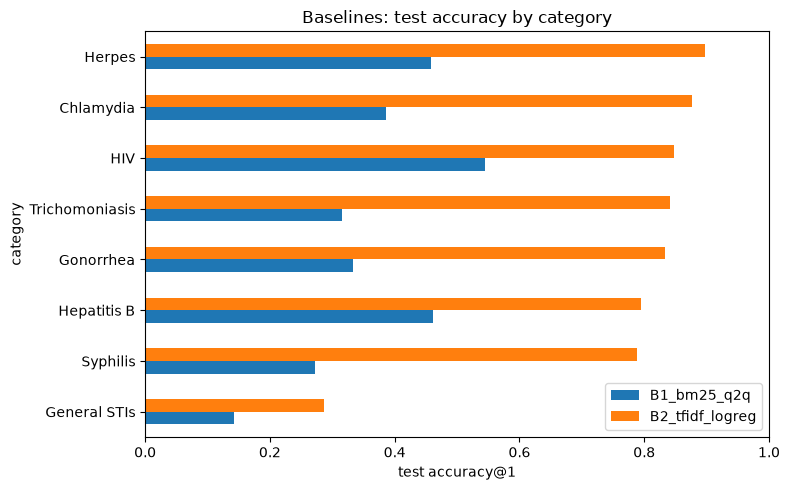

In [12]:
ax = per_cat.drop(columns="n_test").sort_values("B2_tfidf_logreg").plot.barh(figsize=(8, 5))
ax.set_xlabel("test accuracy@1"); ax.set_xlim(0, 1); ax.set_title("Baselines: test accuracy by category")
plt.tight_layout()
plt.savefig("results/figures/baselines_per_category.png", dpi=150)
plt.show()

## 7. Examples (TF-IDF + LR, test set)

In [13]:
scores, true_idx = test_outputs["B2_tfidf_logreg"]
intents = np.array(tfidf_lr.intents)
examples = test[["question", "intent_id"]].copy()
examples["predicted"] = intents[scores.argmax(axis=1)]
examples["confidence"] = scores.max(axis=1).round(3)
examples["bm25_predicted"] = np.array(bm25.intents)[test_outputs["B1_bm25_q2q"][0].argmax(axis=1)]
examples["correct"] = examples["predicted"] == examples["intent_id"]

print("Correct:", examples["correct"].sum(), "/", len(examples))
examples[examples["correct"]].sample(8, random_state=SEED)

Correct: 274 / 333


,question,intent_id,predicted,confidence,bm25_predicted,correct
41,Can I get Gonorrhea from erotic dancing?,Gonorrhea::Transmission/Spread_gonorrhea,Gonorrhea::Transmission/Spread_gonorrhea,0.594,Chlamydia::Transmission_spread_chlamydia,True
201,What are the complications of Herpes during pregnancy?,Herpes::complications_infections,Herpes::complications_infections,0.610,Chlamydia::complications_chlamydia,True
237,What is the best medication for Trich?,Trichomoniasis::Treatment_medication_trichomoniasis,Trichomoniasis::Treatment_medication_trichomoniasis,0.967,Gonorrhea::Treatment/Medication_gonorrhea,True
158,Are there species of Herpes Simplex Virus?,Herpes::types_herpes_simplex_virus,Herpes::types_herpes_simplex_virus,0.964,Herpes::types_herpes_simplex_virus,True
321,Why should I test for Syphilis?,Syphilis::testing_syphilis,Syphilis::testing_syphilis,0.594,Chlamydia::testing_chlamydia,True
280,Chlamydial Genitourinary Infection testing?,Chlamydia::testing_chlamydia,Chlamydia::testing_chlamydia,0.710,Chlamydia::definition_chlamydia,True
311,Can I get Syphilis from kissing?,Syphilis::Transmission/Spread_syphilis,Syphilis::Transmission/Spread_syphilis,0.858,Chlamydia::Transmission_spread_chlamydia,True
248,Where did chlamydia start from?,Chlamydia::origin_chlamydia,Chlamydia::origin_chlamydia,0.967,Chlamydia::origin_chlamydia,True


In [14]:
examples[~examples["correct"]].sample(12, random_state=SEED)

,question,intent_id,predicted,confidence,bm25_predicted,correct
0,What are STDs?,General STIs::definition_stis,General STIs::types_stis,0.933,General STIs::types_stis,False
9,When should I get tested for STIs?,General STIs::testing_stis,Gonorrhea::testing_gonorrhea,0.314,HIV::testing_hiv,False
184,How is HSV spread?,Herpes::Transmission_spread_infections,HIV::Transmission/Spread_hiv,0.309,HIV::Transmission/Spread_hiv,False
61,"I was informed that I have Gonorrhea, what can I do?",Gonorrhea::Treatment/Medication_gonorrhea,Gonorrhea::symptoms_Signs_gonorrhea,0.191,Syphilis::Treatment/Medication_syphilis,False
244,I have never heard the word Chlamydia. What is it?,Chlamydia::definition_chlamydia,Chlamydia::Symptoms_Chlamydia,0.470,Syphilis::signs_symptoms_syphilis,False
315,Is there vaccination against Syphilis?,Syphilis::prevention_syphilis,Syphilis::vaccination_syphilis,0.829,General STIs::vaccination_stis,False
329,Does washing the private parts with warm salty water cure Syphilis?,Syphilis::misconception_syphilis,Syphilis::signs_symptoms_syphilis,0.530,Syphilis::signs_symptoms_syphilis,False
104,Which medicines are used to treat both Hepatitis B and HIV?,Hepatitis B::medication_hepatitis,Herpes::Treatment_medication_infections,0.306,Herpes::Treatment_medication_infections,False
251,What is the background of Chlamydia?,Chlamydia::origin_chlamydia,Gonorrhea::origin_gonorrhea,0.115,Gonorrhea::origin_gonorrhea,False
43,Can circumcision protect me from Gonorrhea?,Gonorrhea::prevention_gonorrhea_No,HIV::prevention_hiv,0.224,Trichomoniasis::prevention_trichomoniasis,False


In [15]:
# wrong intent but right disease?
wrong = examples[~examples["correct"]]
same_category = wrong["predicted"].str.split("::").str[0] == wrong["intent_id"].str.split("::").str[0]
print(f"Wrong predictions in the correct category: {same_category.mean():.1%} of {len(wrong)}")

Wrong predictions in the correct category: 54.2% of 59


In [16]:
# confidence of correct vs wrong predictions
examples.groupby("correct")["confidence"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
False,59.0,0.400,0.213,0.082,0.250,0.340,0.481,0.933
True,274.0,0.824,0.204,0.128,0.751,0.922,0.964,0.997


## 8. Observations
- TF-IDF char 2-5 + LR is clearly the best baseline (test acc@1 0.823, majority 0.042).
- Character n-grams beat word n-grams (0.826 vs 0.733 on val): spelling variants like "Trich", "HSV".
- BM25 is weak (0.360) and gets even the disease wrong about half the time: every disease uses the
  same question templates and the disease name is only one word in them.
- General STIs is the weakest category since its questions don't mention a disease.
- About half the errors are in the right disease but the wrong intent, some look like label noise.